In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

In [ ]:
file_path = "HABs_ScrippsPier_v3.xlsx"

df_raw = pd.read_excel(file_path, sheet_name="Sheet1")

print("Dataset shape:", df_raw.shape)
df_raw.head()

Dataset shape: (523, 21)


,Location_Code,latitude,longitude,time,Temp,Air_Temp,Salinity,Chl_Volume_Filtered,Chl1,Chl2,...,Phaeo1,Phaeo2,Avg_Phaeo,Phosphate,Silicate,Nitrite,Nitrite_Nitrate,Ammonium,Nitrate,Total_Phytoplankton
0,NaN,degrees_north,degrees_east,UTC,degree_C,degree_C,NaN,mL,mg/m3,mg/m3,...,mg/m3,mg/m3,mg/m3,uM,uM,uM,uM,uM,uM,cells/L
1,SIO,32.867,-117.257,2016-08-01T16:21:00Z,24.3,NaN,NaN,100,5.3,4.94,...,0.18,0.39,0.29,0.11,2,0,NaN,0.87,0.53,296630
2,SIO,32.867,-117.257,2016-08-08T16:15:00Z,22.4,NaN,NaN,100,6.86,7.29,...,2.9,2.31,2.61,0.17,3.3,0,NaN,0.53,0.27,223997
3,SIO,32.867,-117.257,2016-08-15T17:09:00Z,22.2,NaN,NaN,100,3.71,5.07,...,3.62,5.69,4.65,0.16,3.6,0,NaN,0.71,0.3,161229
4,SIO,32.867,-117.257,2016-08-22T15:44:00Z,19.1,NaN,NaN,100,2.12,2.05,...,0.66,0.72,0.69,0.29,4.5,0,NaN,1.05,0.45,190767


In [ ]:
# Save the measurement units
units = df_raw.iloc[0].copy()

# Remove the units row from the dataset
df = df_raw.iloc[1:].copy()

# Reset the row index
df = df.reset_index(drop=True)

print("Number of observations:", len(df))
df.head()

Number of observations: 522


,Location_Code,latitude,longitude,time,Temp,Air_Temp,Salinity,Chl_Volume_Filtered,Chl1,Chl2,...,Phaeo1,Phaeo2,Avg_Phaeo,Phosphate,Silicate,Nitrite,Nitrite_Nitrate,Ammonium,Nitrate,Total_Phytoplankton
0,SIO,32.867,-117.257,2016-08-01T16:21:00Z,24.3,NaN,NaN,100,5.3,4.94,...,0.18,0.39,0.29,0.11,2,0,NaN,0.87,0.53,296630
1,SIO,32.867,-117.257,2016-08-08T16:15:00Z,22.4,NaN,NaN,100,6.86,7.29,...,2.9,2.31,2.61,0.17,3.3,0,NaN,0.53,0.27,223997
2,SIO,32.867,-117.257,2016-08-15T17:09:00Z,22.2,NaN,NaN,100,3.71,5.07,...,3.62,5.69,4.65,0.16,3.6,0,NaN,0.71,0.3,161229
3,SIO,32.867,-117.257,2016-08-22T15:44:00Z,19.1,NaN,NaN,100,2.12,2.05,...,0.66,0.72,0.69,0.29,4.5,0,NaN,1.05,0.45,190767
4,SIO,32.867,-117.257,2016-08-29T16:05:00Z,20.9,NaN,NaN,100,2.21,2.33,...,0.9,0.9,0.9,0.24,3.6,0,NaN,0.61,0.29,126768


In [ ]:
df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)

print("Start date:", df["time"].min())
print("End date:", df["time"].max())

Start date: 2016-08-01 16:21:00+00:00
End date: 2026-07-27 18:16:00+00:00


In [ ]:
numeric_columns = [
    "Temp",
    "Chl1",
    "Chl2",
    "Avg_Chloro",
    "Phaeo1",
    "Phaeo2",
    "Avg_Phaeo",
    "Phosphate",
    "Silicate",
    "Nitrite",
    "Ammonium",
    "Nitrate",
    "Total_Phytoplankton"
]

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

df[numeric_columns].dtypes

,0
Temp,float64
Chl1,float64
Chl2,float64
Avg_Chloro,float64
Phaeo1,float64
Phaeo2,float64
Avg_Phaeo,float64
Phosphate,float64
Silicate,float64
Nitrite,float64


In [ ]:
print("Number of observations:", df.shape[0])
print("Number of columns:", df.shape[1])

print("Start date:", df["time"].min())
print("End date:", df["time"].max())

print("Duplicate timestamps:", df["time"].duplicated().sum())

Number of observations: 522
Number of columns: 21
Start date: 2016-08-01 16:21:00+00:00
End date: 2026-07-27 18:16:00+00:00
Duplicate timestamps: 0


In [ ]:
missing_summary = pd.DataFrame({
    "Missing_n": df.isna().sum(),
    "Missing_percent": df.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing_percent",
    ascending=False
)

missing_summary.round(2)

,Missing_n,Missing_percent
Air_Temp,522,100.00
Salinity,522,100.00
Nitrite_Nitrate,522,100.00
Total_Phytoplankton,25,4.79
Ammonium,3,0.57
Nitrate,2,0.38
Phosphate,2,0.38
Nitrite,2,0.38
Silicate,2,0.38
Chl2,1,0.19


In [ ]:
unique_values = df.nunique(dropna=True).sort_values()

unique_values

,0
Salinity,0
Air_Temp,0
Nitrite_Nitrate,0
Location_Code,1
Chl_Volume_Filtered,1
longitude,1
latitude,1
Nitrite,12
Phosphate,74
Silicate,92


In [ ]:
constant_columns = unique_values[unique_values <= 1]

print("Constant or empty columns:")
print(constant_columns)

Constant or empty columns:
Salinity               0
Air_Temp               0
Nitrite_Nitrate        0
Location_Code          1
Chl_Volume_Filtered    1
longitude              1
latitude               1
dtype: int64


In [ ]:
selected_columns = [
    "Avg_Chloro",
    "Temp",
    "Phosphate",
    "Silicate",
    "Nitrite",
    "Ammonium",
    "Nitrate",
    "Avg_Phaeo",
    "Total_Phytoplankton"
]

summary_statistics = df[selected_columns].describe().T

summary_statistics["missing_n"] = df[selected_columns].isna().sum()
summary_statistics["missing_percent"] = (
    df[selected_columns].isna().mean() * 100
)

summary_statistics = summary_statistics[
    [
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max",
        "missing_n",
        "missing_percent"
    ]
]

summary_statistics.round(2)

,count,mean,std,min,25%,50%,75%,max,missing_n,missing_percent
Avg_Chloro,522.0,5.20,27.55,0.16,1.36,2.04,3.30,467.66,0,0.00
Temp,522.0,18.00,2.75,13.10,15.70,17.50,19.98,25.50,0,0.00
Phosphate,520.0,0.25,0.20,0.00,0.14,0.22,0.32,1.26,2,0.38
Silicate,520.0,3.22,2.25,0.00,1.90,2.70,3.90,16.60,2,0.38
Nitrite,520.0,0.01,0.04,0.00,0.00,0.00,0.00,0.42,2,0.38
Ammonium,519.0,1.39,6.30,0.00,0.24,0.46,0.80,63.18,3,0.57
Nitrate,520.0,0.52,1.06,0.00,0.00,0.23,0.56,11.80,2,0.38
Avg_Phaeo,522.0,0.95,3.29,0.00,0.40,0.59,0.86,54.70,0,0.00
Total_Phytoplankton,497.0,343564.29,850555.69,15225.00,85110.00,161229.00,314153.00,9774726.00,25,4.79


In [ ]:
df["Calculated_Avg_Chloro"] = df[["Chl1", "Chl2"]].mean(
    axis=1,
    skipna=True
)

df["Avg_Chloro_Difference"] = (
    df["Avg_Chloro"] - df["Calculated_Avg_Chloro"]
).abs()

df.loc[
    df["Avg_Chloro_Difference"] > 0.01,
    [
        "time",
        "Chl1",
        "Chl2",
        "Avg_Chloro",
        "Calculated_Avg_Chloro",
        "Avg_Chloro_Difference"
    ]
]

,time,Chl1,Chl2,Avg_Chloro,Calculated_Avg_Chloro,Avg_Chloro_Difference
197,2020-05-11 19:50:00+00:00,84.5,68.05,73.61,76.275,2.665


In [ ]:
#Chlorophyll-a time-series plot

# Sort observations chronologically
df = df.sort_values("time").reset_index(drop=True)

# Calculate a 4-week rolling median
df["Chl_4week_median"] = (
    df["Avg_Chloro"]
    .rolling(window=4, min_periods=1)
    .median()
)

df[["time", "Avg_Chloro", "Chl_4week_median"]].head()

,time,Avg_Chloro,Chl_4week_median
0,2016-08-01 16:21:00+00:00,5.12,5.120
1,2016-08-08 16:15:00+00:00,7.07,6.095
2,2016-08-15 17:09:00+00:00,4.39,5.120
3,2016-08-22 15:44:00+00:00,2.08,4.755
4,2016-08-29 16:05:00+00:00,2.27,3.330


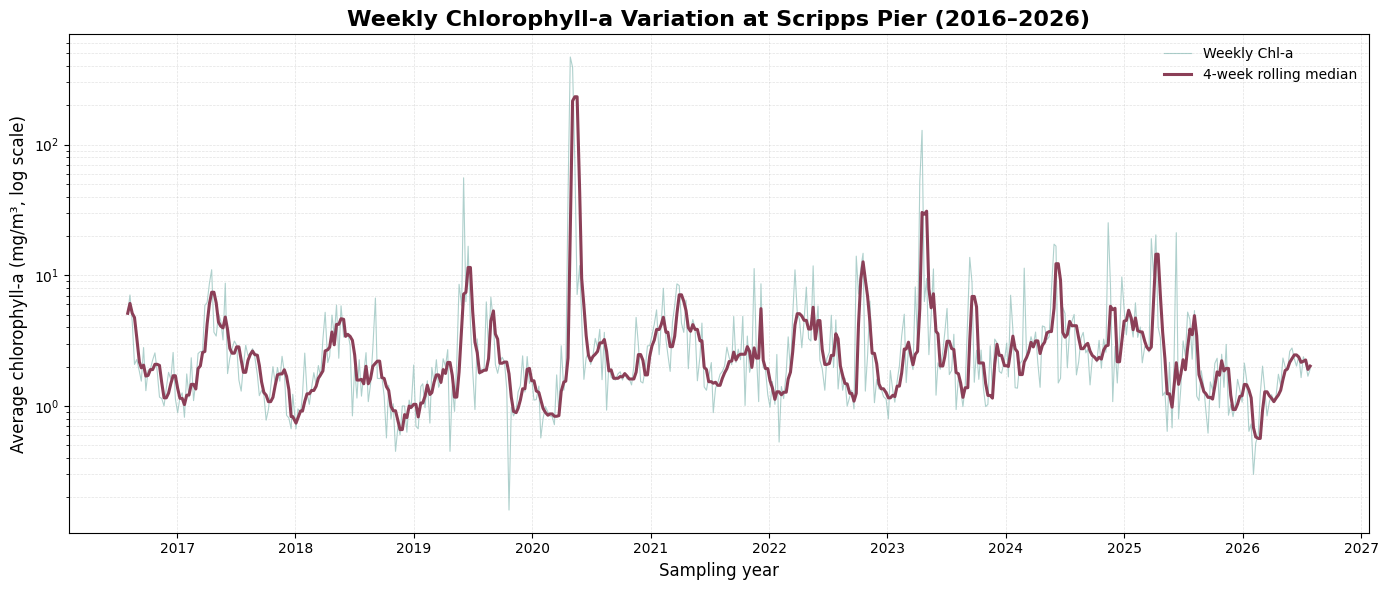

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 6))

# Weekly observations
ax.plot(
    df["time"],
    df["Avg_Chloro"],
    color="#84B8B2",
    linewidth=0.8,
    alpha=0.65,
    label="Weekly Chl-a"
)

# Four-week rolling median
ax.plot(
    df["time"],
    df["Chl_4week_median"],
    color="#8B3F57",
    linewidth=2.2,
    label="4-week rolling median"
)

ax.set_yscale("log")

ax.set_title(
    "Weekly Chlorophyll-a Variation at Scripps Pier (2016–2026)",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Sampling year", fontsize=12)
ax.set_ylabel("Average chlorophyll-a (mg/m³, log scale)", fontsize=12)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(
    True,
    which="both",
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

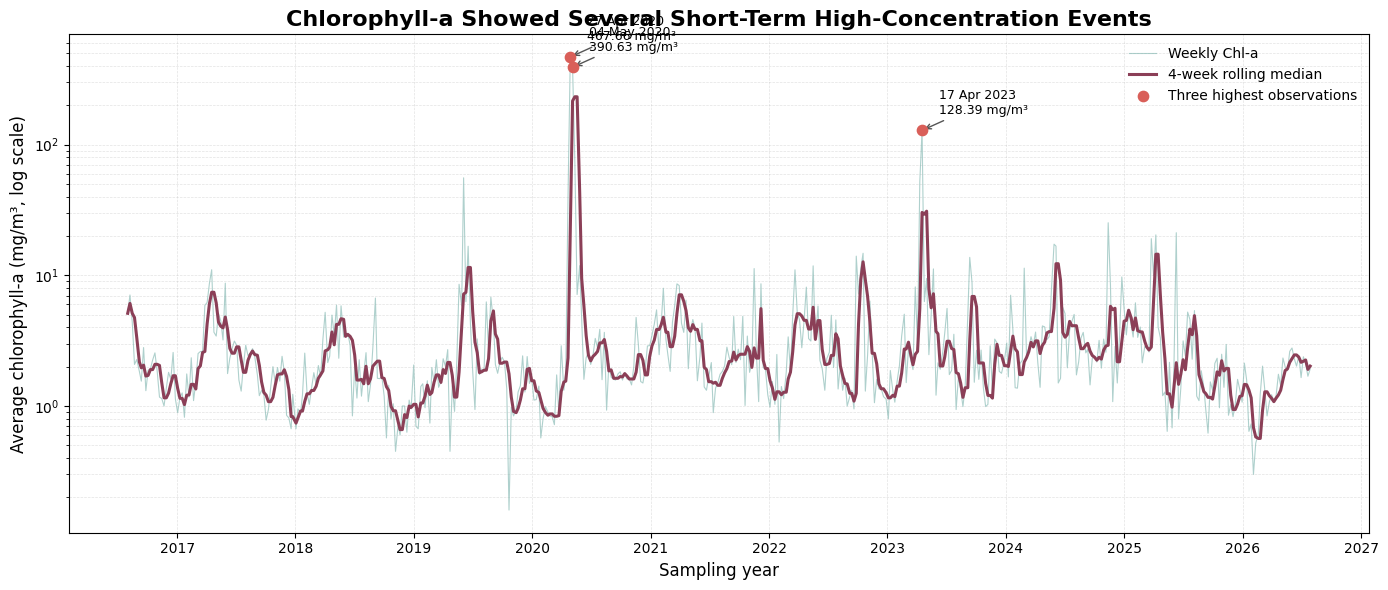

In [ ]:
top_peaks = df.nlargest(3, "Avg_Chloro")

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    df["time"],
    df["Avg_Chloro"],
    color="#84B8B2",
    linewidth=0.8,
    alpha=0.65,
    label="Weekly Chl-a"
)

ax.plot(
    df["time"],
    df["Chl_4week_median"],
    color="#8B3F57",
    linewidth=2.2,
    label="4-week rolling median"
)

ax.scatter(
    top_peaks["time"],
    top_peaks["Avg_Chloro"],
    color="#D95F59",
    s=55,
    zorder=5,
    label="Three highest observations"
)

for _, row in top_peaks.iterrows():
    annotation = (
        f'{row["time"].strftime("%d %b %Y")}\n'
        f'{row["Avg_Chloro"]:.2f} mg/m³'
    )

    ax.annotate(
        annotation,
        xy=(row["time"], row["Avg_Chloro"]),
        xytext=(12, 12),
        textcoords="offset points",
        fontsize=9,
        arrowprops={
            "arrowstyle": "->",
            "color": "#555555"
        }
    )

ax.set_yscale("log")

ax.set_title(
    "Chlorophyll-a Showed Several Short-Term High-Concentration Events",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Sampling year", fontsize=12)
ax.set_ylabel("Average chlorophyll-a (mg/m³, log scale)", fontsize=12)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(
    True,
    which="both",
    linestyle="--",
    linewidth=0.5,
    alpha=0.35
)

ax.legend(frameon=False, loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
plt.savefig(
    "chlorophyll_time_series.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
correlation_columns = [
    "Avg_Chloro",
    "Temp",
    "Phosphate",
    "Silicate",
    "Nitrite",
    "Ammonium",
    "Nitrate",
    "Avg_Phaeo",
    "Total_Phytoplankton"
]

correlation_data = df[correlation_columns].copy()

In [ ]:
spearman_corr = correlation_data.corr(method="spearman")

spearman_corr.round(3)

,Avg_Chloro,Temp,Phosphate,Silicate,Nitrite,Ammonium,Nitrate,Avg_Phaeo,Total_Phytoplankton
Avg_Chloro,1.000,-0.059,0.014,0.395,0.039,-0.033,0.055,0.684,0.649
Temp,-0.059,1.000,-0.719,-0.470,-0.242,-0.294,-0.521,-0.153,0.136
Phosphate,0.014,-0.719,1.000,0.420,0.238,0.413,0.504,0.138,-0.184
Silicate,0.395,-0.470,0.420,1.000,0.181,0.207,0.263,0.397,0.121
Nitrite,0.039,-0.242,0.238,0.181,1.000,0.260,0.291,0.066,-0.095
Ammonium,-0.033,-0.294,0.413,0.207,0.260,1.000,0.270,0.150,-0.145
Nitrate,0.055,-0.521,0.504,0.263,0.291,0.270,1.000,0.130,-0.044
Avg_Phaeo,0.684,-0.153,0.138,0.397,0.066,0.150,0.130,1.000,0.415
Total_Phytoplankton,0.649,0.136,-0.184,0.121,-0.095,-0.145,-0.044,0.415,1.000


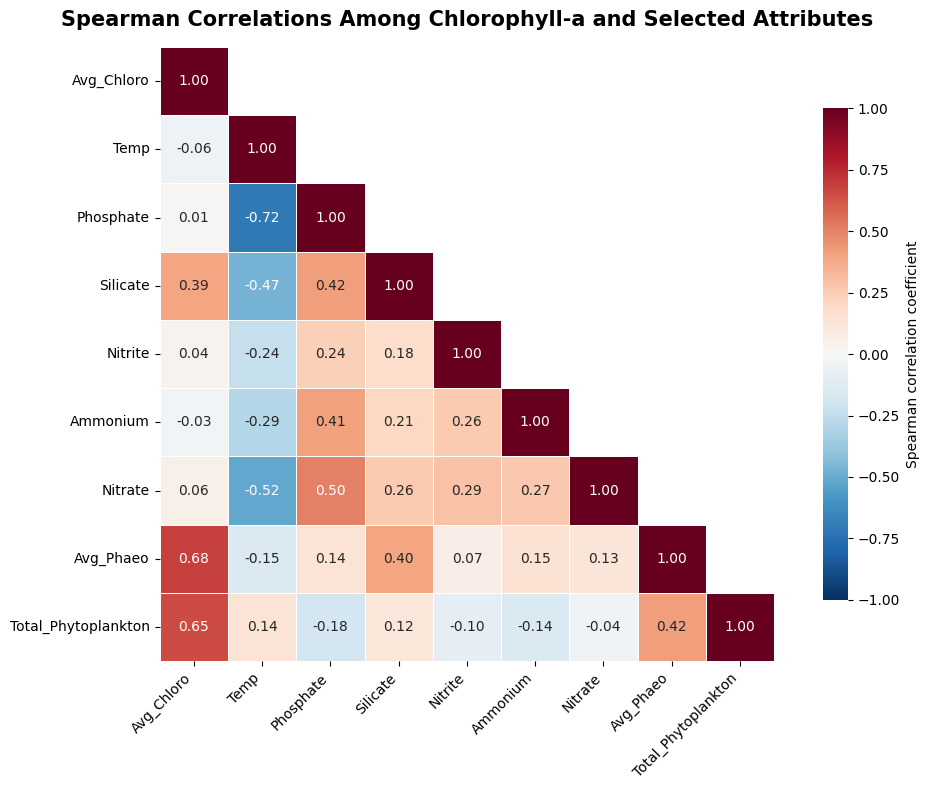

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Create a mask to hide the upper half
mask = np.triu(
    np.ones_like(spearman_corr, dtype=bool),
    k=1
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    spearman_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.7,
    linecolor="white",
    cbar_kws={
        "label": "Spearman correlation coefficient",
        "shrink": 0.8
    }
)

plt.title(
    "Spearman Correlations Among Chlorophyll-a and Selected Attributes",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "spearman_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [ ]:
chl_correlations = (
    spearman_corr["Avg_Chloro"]
    .drop("Avg_Chloro")
    .sort_values(ascending=False)
)

chl_correlations.round(3)

,Avg_Chloro
Avg_Phaeo,0.684
Total_Phytoplankton,0.649
Silicate,0.395
Nitrate,0.055
Nitrite,0.039
Phosphate,0.014
Ammonium,-0.033
Temp,-0.059


In [ ]:
sample_sizes = {}

for column in correlation_columns:
    if column != "Avg_Chloro":
        pair_data = df[["Avg_Chloro", column]].dropna()
        sample_sizes[column] = len(pair_data)

sample_size_table = pd.DataFrame({
    "Spearman_rho": chl_correlations,
    "Sample_size": pd.Series(sample_sizes)
})

sample_size_table = sample_size_table.loc[
    chl_correlations.index
]

sample_size_table.round(3)

,Spearman_rho,Sample_size
Avg_Phaeo,0.684,522
Total_Phytoplankton,0.649,497
Silicate,0.395,520
Nitrate,0.055,520
Nitrite,0.039,520
Phosphate,0.014,520
Ammonium,-0.033,519
Temp,-0.059,522


In [ ]:
plt.tight_layout()

plt.savefig(
    "spearman_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFile saved:", os.path.exists(
    "spearman_correlation_heatmap.png"
))

Current folder:
/content

File saved: True


In [ ]:
from IPython.display import FileLink

FileLink("spearman_correlation_heatmap.png")

/content/spearman_correlation_heatmap.png

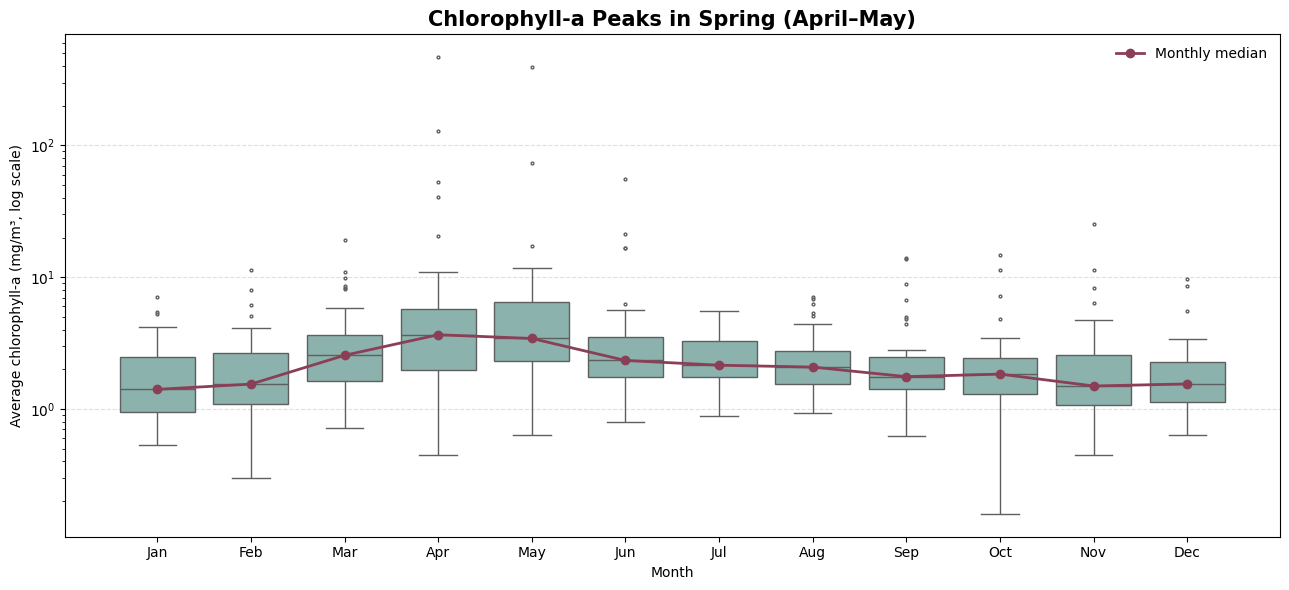

In [ ]:
# Seasonal breakdown of Avg_Ch-A
df["month"] = df["time"].dt.month
month_labels = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(13, 6))

sns.boxplot(
    data=df,
    x="month",
    y="Avg_Chloro",
    color="#84B8B2",
    fliersize=2,
    linewidth=1,
    ax=ax
)

medians = df.groupby("month")["Avg_Chloro"].median()
ax.plot(range(12), medians.values, color="#8B3F57", marker="o",
        linewidth=2, zorder=5, label="Monthly median")

ax.set_yscale("log")
ax.set_xticks(range(12))
ax.set_xticklabels(month_labels)
ax.set_title("Chlorophyll-a Peaks in Spring (April–May)", fontsize=15, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Average chlorophyll-a (mg/m³, log scale)")
ax.legend(frameon=False)
ax.grid(True, which="major", axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("chloro_seasonal_boxplot.png", dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


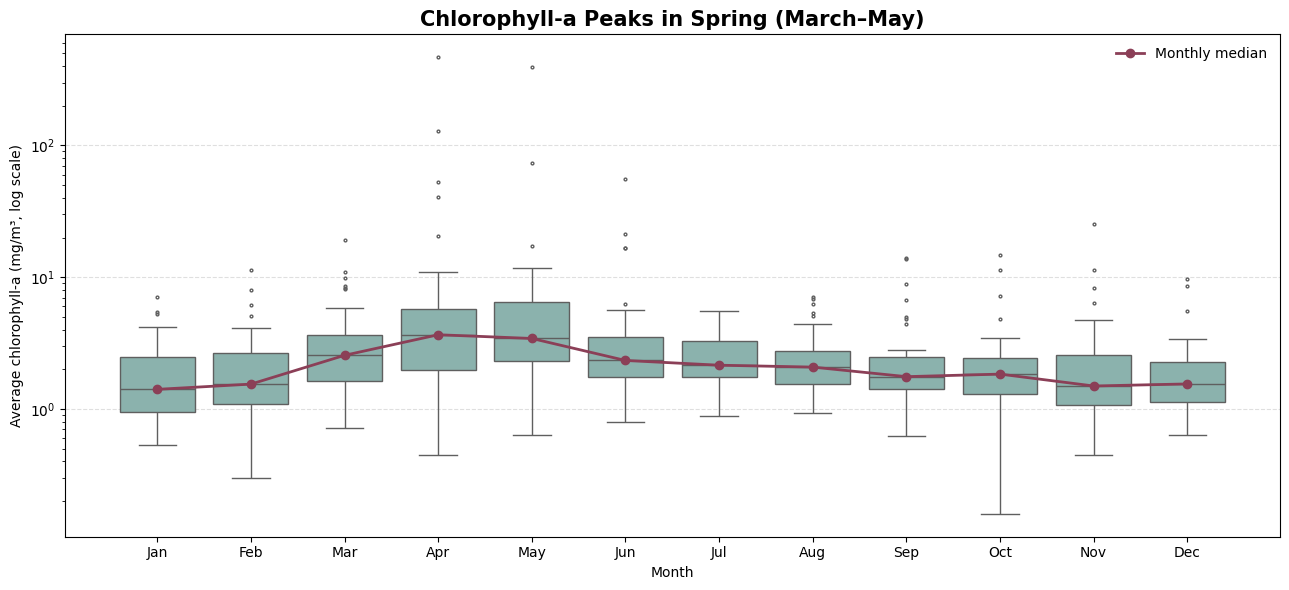

In [ ]:
# Seasonal breakdown of Avg_Ch-A (Mar-Apr)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/DATA_Mining-Project/HABs_ScrippsPier_v3.xlsx"
df_raw = pd.read_excel(file_path, sheet_name="Sheet1")
df = df_raw.iloc[1:].copy().reset_index(drop=True)
df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)
df["Avg_Chloro"] = pd.to_numeric(df["Avg_Chloro"], errors="coerce")

# Seasonal breakdown of Avg_Ch-A
df["month"] = df["time"].dt.month
month_labels = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(13, 6))

sns.boxplot(
    data=df,
    x="month",
    y="Avg_Chloro",
    color="#84B8B2",
    fliersize=2,
    linewidth=1,
    ax=ax
)

medians = df.groupby("month")["Avg_Chloro"].median()
ax.plot(range(12), medians.values, color="#8B3F57", marker="o",
        linewidth=2, zorder=5, label="Monthly median")

ax.set_yscale("log")
ax.set_xticks(range(12))
ax.set_xticklabels(month_labels)
ax.set_title("Chlorophyll-a Peaks in Spring (March–May)", fontsize=15, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Average chlorophyll-a (mg/m³, log scale)")
ax.legend(frameon=False)
ax.grid(True, which="major", axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("chloro_seasonal_boxplot.png", dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
n = 522
skewness = 14.61
mean = 5.20, median = 2.04


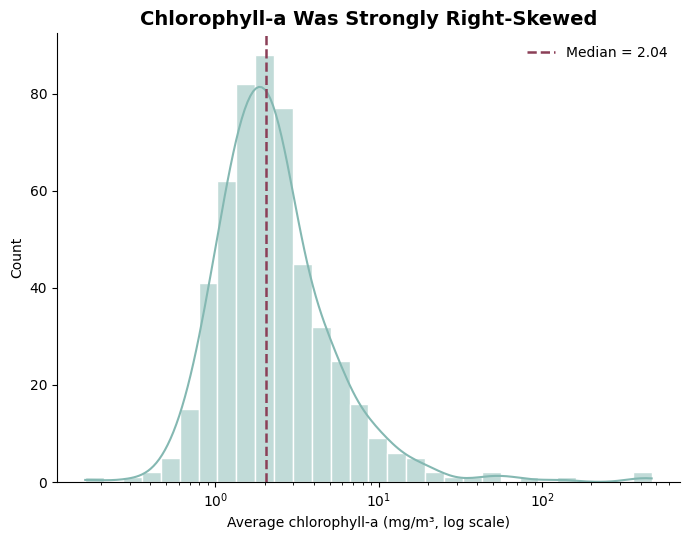

In [ ]:
#Chlorophyll-a Was Strongly Right-Skewed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/DATA_Mining-Project/HABs_ScrippsPier_v3.xlsx"
df_raw = pd.read_excel(file_path, sheet_name="Sheet1")
df = df_raw.iloc[1:].copy().reset_index(drop=True)
df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)
df["Avg_Chloro"] = pd.to_numeric(df["Avg_Chloro"], errors="coerce")

s = df["Avg_Chloro"].dropna()
print(f"n = {len(s)}")
print(f"skewness = {s.skew():.2f}")
print(f"mean = {s.mean():.2f}, median = {s.median():.2f}")

COLOR_TEAL   = "#84B8B2"
COLOR_MAROON = "#8B3F57"

fig, ax = plt.subplots(figsize=(7, 5.5))

sns.histplot(
    s, bins=30, kde=True, log_scale=True,
    color=COLOR_TEAL, edgecolor="white", ax=ax
)
ax.axvline(s.median(), color=COLOR_MAROON, linestyle="--", linewidth=1.8,
           label=f"Median = {s.median():.2f}")
ax.set_xlabel("Average chlorophyll-a (mg/m³, log scale)")
ax.set_ylabel("Count")
ax.set_title("Chlorophyll-a Was Strongly Right-Skewed", fontsize=14, fontweight="bold")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig("distribution_chla_log.png", dpi=1200, facecolor="white")
plt.show()

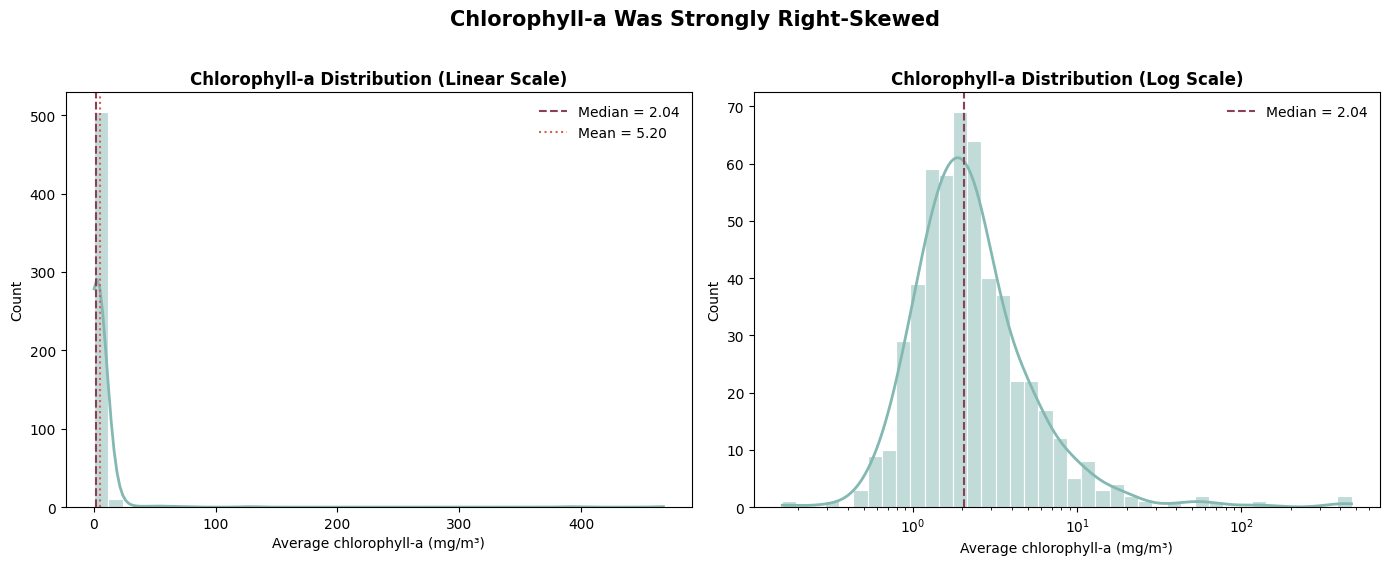

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---- โหลดและทำความสะอาดข้อมูล ----
file_path = "HABs_ScrippsPier_v3.xlsx"
df_raw = pd.read_excel(file_path, sheet_name="Sheet1")
df = df_raw.iloc[1:].copy().reset_index(drop=True)
df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)

numeric_columns = ["Temp","Chl1","Chl2","Avg_Chloro","Phaeo1","Phaeo2","Avg_Phaeo",
    "Phosphate","Silicate","Nitrite","Ammonium","Nitrate","Total_Phytoplankton"]
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")
df = df.sort_values("time").reset_index(drop=True)

# ---- กราฟ 1: Distribution of Avg_Chloro (linear vs log scale) ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.histplot(
    df["Avg_Chloro"].dropna(),
    bins=40,
    color="#84B8B2",
    edgecolor="white",
    kde=True,
    line_kws={"color": "#8B3F57", "linewidth": 2},
    ax=axes[0]
)
axes[0].axvline(df["Avg_Chloro"].median(), color="#8B3F57", linestyle="--",
                 label=f'Median = {df["Avg_Chloro"].median():.2f}')
axes[0].axvline(df["Avg_Chloro"].mean(), color="#D95F59", linestyle=":",
                 label=f'Mean = {df["Avg_Chloro"].mean():.2f}')
axes[0].set_title("Chlorophyll-a Distribution (Linear Scale)", fontweight="bold")
axes[0].set_xlabel("Average chlorophyll-a (mg/m³)")
axes[0].set_ylabel("Count")
axes[0].legend(frameon=False)

sns.histplot(
    df["Avg_Chloro"].dropna(),
    bins=40,
    color="#84B8B2",
    edgecolor="white",
    log_scale=True,
    kde=True,
    line_kws={"color": "#8B3F57", "linewidth": 2},
    ax=axes[1]
)
axes[1].axvline(df["Avg_Chloro"].median(), color="#8B3F57", linestyle="--",
                 label=f'Median = {df["Avg_Chloro"].median():.2f}')
axes[1].set_title("Chlorophyll-a Distribution (Log Scale)", fontweight="bold")
axes[1].set_xlabel("Average chlorophyll-a (mg/m³)")
axes[1].set_ylabel("Count")
axes[1].legend(frameon=False)

fig.suptitle("Chlorophyll-a Was Strongly Right-Skewed", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("chloro_distribution.png", dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

In [1]:
#Chlorophyll-a Has a 5 Week Memory
from statsmodels.tsa.stattools import acf

COLOR_TEAL = '#84B8B2'
COLOR_MAROON = '#8B3F57'
COLOR_GRAY = '#C9C4B8'

df['Avg_Chloro'] = pd.to_numeric(df['Avg_Chloro'], errors='coerce')   # <-- added: fixes dtype only, values unchanged

s_log = np.log1p(df['Avg_Chloro'].dropna())
n = len(s_log)
nlags = 15
vals = acf(s_log, nlags=nlags)
ci = 1.96 / np.sqrt(n)
lags = np.arange(nlags + 1)

significant = np.abs(vals) > ci
significant[0] = False

fig, ax = plt.subplots(figsize=(9, 5))

ax.fill_between(lags, -ci, ci, color=COLOR_GRAY, alpha=0.35, zorder=1,
                 label='95% confidence band (not significant)')

colors = [COLOR_MAROON if sig else '#B7AFA0' for sig in significant]
colors[0] = COLOR_MAROON
ax.bar(lags, vals, color=colors, width=0.55, zorder=3)
ax.vlines(lags, 0, vals, color=colors, linewidth=1.4, zorder=2)

for lag, v, sig in zip(lags, vals, significant):
    if sig or lag == 0:
        ax.annotate(f'{v:.2f}', (lag, v), textcoords='offset points',
                     xytext=(0, 6 if v >= 0 else -14), ha='center',
                     fontsize=8.5, color=COLOR_MAROON, fontweight='bold')

ax.axhline(0, color='#3F3F3F', linewidth=0.8, zorder=2)
ax.set_ylim(-0.25, 1.12)
ax.set_xlim(-0.7, nlags + 0.7)
ax.set_xticks(lags)

ax.set_title('Chlorophyll-a Has a 5 Week Memory', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Lag (weeks)', fontsize=11)
ax.set_ylabel('Autocorrelation', fontsize=11)
ax.legend(loc='upper right', frameon=False, fontsize=9)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['left'].set_color('#999999')
ax.spines['bottom'].set_color('#999999')
ax.tick_params(colors='#555555')
ax.grid(axis='y', linestyle='--', alpha=0.3, zorder=0)

plt.tight_layout()
plt.savefig('acf_chla.png', dpi=1200, facecolor='white')
plt.show()

NameError: name 'pd' is not defined

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


KeyboardInterrupt: 

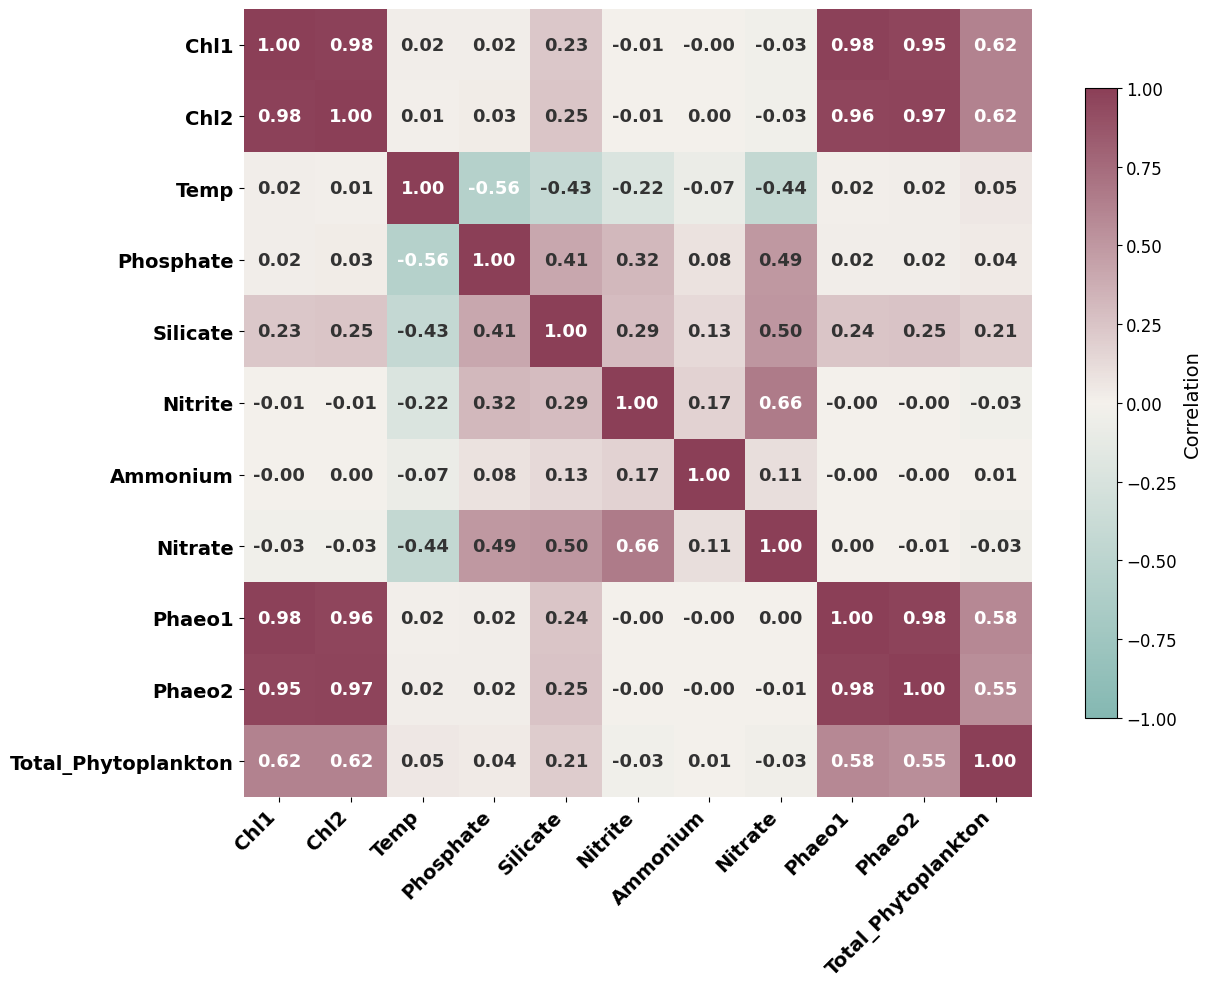

In [ ]:
#Pearson
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from google.colab import drive

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/DATA_Mining-Project/HABs_ScrippsPier_v3.xlsx"
df_raw = pd.read_excel(file_path, sheet_name="Sheet1")
df = df_raw.iloc[1:].copy().reset_index(drop=True)
df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)

cols_target     = ["Chl1", "Chl2"]
cols_predictor  = ["Temp", "Phosphate", "Silicate", "Nitrite", "Ammonium", "Nitrate"]
cols_diagnostic = ["Phaeo1", "Phaeo2", "Total_Phytoplankton"]
cols = cols_target + cols_predictor + cols_diagnostic

for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

corr = df[cols].corr()

COLOR_TEAL   = "#84B8B2"
COLOR_MAROON = "#8B3F57"
COLOR_MID    = "#F4F1EC"

cmap = mcolors.LinearSegmentedColormap.from_list(
    "teal_maroon_diverging", [COLOR_TEAL, COLOR_MID, COLOR_MAROON]
)

fig, ax = plt.subplots(figsize=(13, 10))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)

ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right", fontsize=14, fontweight="bold")
ax.set_yticklabels(cols, fontsize=14, fontweight="bold")

for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr.iloc[i, j]
        text_color = "white" if abs(val) > 0.55 else "#333333"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                 fontsize=13, color=text_color, fontweight="bold")

cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Correlation", fontsize=14)
cbar.ax.tick_params(labelsize=12)

#ax.set_title("Relationships Between Chl-a and Selected Attributes",
             #fontsize=20, fontweight="bold", pad=18)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=1200, facecolor="white")
plt.show()

print(corr[["Chl1", "Chl2"]].sort_values(by="Chl1", ascending=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


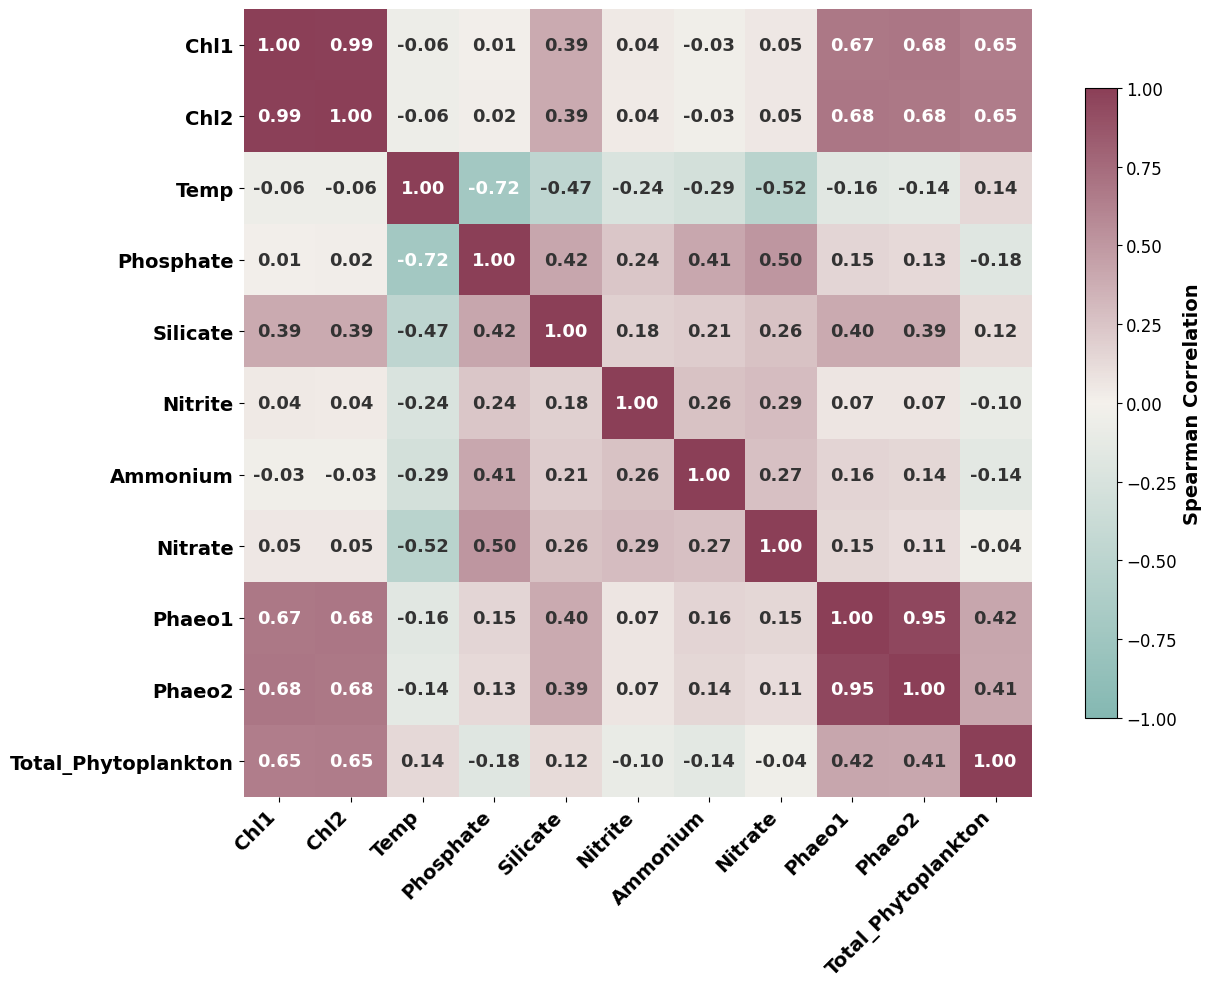

                         Chl1      Chl2
Chl1                 1.000000  0.992110
Chl2                 0.992110  1.000000
Phaeo2               0.681378  0.679058
Phaeo1               0.672863  0.683765
Total_Phytoplankton  0.646635  0.649624
Silicate             0.391508  0.392423
Nitrate              0.052088  0.051415
Nitrite              0.040803  0.036802
Phosphate            0.011983  0.015925
Ammonium            -0.034007 -0.031549
Temp                -0.059313 -0.055999


In [ ]:
#Spearman
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from google.colab import drive

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/DATA_Mining-Project/HABs_ScrippsPier_v3.xlsx"
df_raw = pd.read_excel(file_path, sheet_name="Sheet1")
df = df_raw.iloc[1:].copy().reset_index(drop=True)
df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)

cols_target     = ["Chl1", "Chl2"]
cols_predictor  = ["Temp", "Phosphate", "Silicate", "Nitrite", "Ammonium", "Nitrate"]
cols_diagnostic = ["Phaeo1", "Phaeo2", "Total_Phytoplankton"]
cols = cols_target + cols_predictor + cols_diagnostic

for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

corr = df[cols].corr(method="spearman")

COLOR_TEAL   = "#84B8B2"
COLOR_MAROON = "#8B3F57"
COLOR_MID    = "#F4F1EC"

cmap = mcolors.LinearSegmentedColormap.from_list(
    "teal_maroon_diverging", [COLOR_TEAL, COLOR_MID, COLOR_MAROON]
)

fig, ax = plt.subplots(figsize=(13, 10))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)

ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right", fontsize=14, fontweight="bold")
ax.set_yticklabels(cols, fontsize=14, fontweight="bold")

for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr.iloc[i, j]
        text_color = "white" if abs(val) > 0.55 else "#333333"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                 fontsize=13, color=text_color, fontweight="bold")

cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Spearman Correlation", fontsize=14, fontweight="bold")
cbar.ax.tick_params(labelsize=12)

#ax.set_title("Relationships Between Chl-a and Selected Attributes (Spearman)",
             #fontsize=20, fontweight="bold", pad=18)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig("correlation_heatmap_spearman.png", dpi=1200, facecolor="white")
plt.show()

print(corr[["Chl1", "Chl2"]].sort_values(by="Chl1", ascending=False))